In [4]:
import tensorflow as tf
import pandas as pd
import numpy as np
import sklearn
import matplotlib

print(tf.__version__)
print("CNN Environment Ready")


2.21.0
CNN Environment Ready


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [6]:
train_dir = r"D:\cnn_image\cnn_image_quiz_3000\train"
val_dir = r"D:\cnn_image\cnn_image_quiz_3000\validation"
test_dir = r"D:\cnn_image\cnn_image_quiz_3000\test"

In [7]:
train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(32, 32),
    batch_size=32
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(32, 32),
    batch_size=32
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(32, 32),
    batch_size=32,
    shuffle=False
)

Found 2100 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 450 files belonging to 3 classes.


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Rescaling

model = Sequential([
    Rescaling(1./255, input_shape=(32, 32, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation='relu'),

    Dense(3, activation='softmax')
])

c:\Users\Daniii\anaconda3\envs\cnn_env\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Input(shape=(32, 32, 3)),
    Rescaling(1./255),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,107 (652.76 KB)

 Trainable params: 167,107 (652.76 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10


c:\Users\Daniii\anaconda3\envs\cnn_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - accuracy: 0.4229 - loss: 1.0700 - val_accuracy: 0.5267 - val_loss: 0.9848
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - accuracy: 0.5167 - loss: 0.9372 - val_accuracy: 0.5867 - val_loss: 0.8738
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.5862 - loss: 0.8624 - val_accuracy: 0.5911 - val_loss: 0.8519
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.6110 - loss: 0.8151 - val_accuracy: 0.6311 - val_loss: 0.8208
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.6310 - loss: 0.7965 - val_accuracy: 0.6067 - val_loss: 0.8372
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.6548 - loss: 0.7445 - val_accuracy: 0.6022 - val_loss: 0.7979
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.6824 - loss: 0.7021 - val_accuracy: 0.6378 - val_loss: 0.8141
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.7105 - loss: 0.6462 - val_accuracy: 0.6200 - val_loss: 

In [13]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.6556 - loss: 0.8181
Test Loss: 0.818062424659729
Test Accuracy: 0.6555555462837219


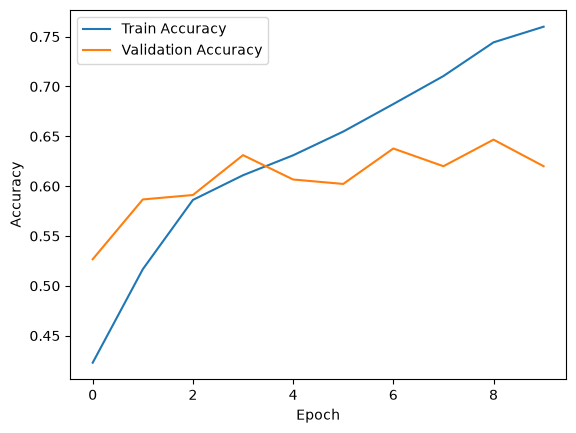

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

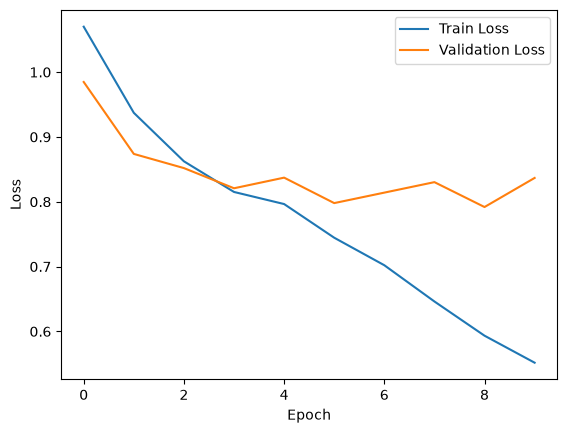

In [15]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [16]:
import numpy as np
import tensorflow as tf

class_names = train_data.class_names

img_path = r"D:\cnn_image\cnn_image_quiz_3000\test\cat\cat_0000.png"

img = tf.keras.utils.load_img(
    img_path,
    target_size=(32, 32)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array)

score = tf.nn.softmax(predictions[0])

print("Predicted Class:", class_names[np.argmax(score)])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step
Predicted Class: cat


In [17]:
predictions = model.predict(img_array)

predicted_index = np.argmax(predictions[0])

print("Predicted Class:", class_names[predicted_index])
print("Confidence:", np.max(predictions[0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step
Predicted Class: cat
Confidence: 0.59779537


In [17]:
model.save("cnn_model.keras")

In [20]:
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

# Load trained model
model = tf.keras.models.load_model("cnn_model.keras")

class_names = ["cat", "dog", "horse"]

st.title("Cat Dog Horse CNN Classifier")

uploaded_file = st.file_uploader(
    "Upload an image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")

    st.image(image, caption="Uploaded Image")

    image = image.resize((32, 32))
    img_array = np.array(image)

    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = np.max(prediction[0]) * 100
    st.success(f"Prediction: {predicted_class}")
    st.write(f"Confidence: {confidence:.2f}%")

ModuleNotFoundError: No module named 'streamlit'